<a href="https://colab.research.google.com/github/manveethjain8/Machine_Learning_II/blob/main/som_unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unsupervised Learning with a Self-Organizing Map (SOM)

This notebook reads a dataset, preprocesses it, trains a **Self-Organizing Map** (implemented from scratch in NumPy, so there are no extra dependencies), and then interprets the result with:

1. Training diagnostics (quantization & topographic error)
2. **U-Matrix** (cluster boundaries on the map)
3. **Hit map** (how many samples land on each neuron)
4. **Component planes** (how each feature is distributed over the map)
5. **Clustering the neurons** (K-Means on the SOM codebook) and mapping clusters back to the data
6. Exporting results to CSV

**How to use your own data:** set `DATA_PATH` in the configuration cell to your CSV file. If it is left as `None`, the notebook uses the Wine dataset from scikit-learn as a demo.

## 1. Imports & configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams["figure.dpi"] = 110

In [2]:
# ----------------------------- CONFIGURATION -----------------------------
DATA_PATH    = None      # e.g. "my_data.csv". None -> use the built-in Wine demo dataset
CSV_KWARGS   = {}        # e.g. {"sep": ";"} for semicolon-separated files
LABEL_COL    = None      # optional column with known classes (used ONLY for interpretation, never for training)
DROP_COLS    = []        # columns to ignore (IDs, free text, etc.)

MAP_ROWS     = None      # SOM grid rows    (None -> chosen automatically)
MAP_COLS     = None      # SOM grid columns (None -> chosen automatically)
N_ITERATIONS = 20000     # number of training steps
LEARNING_RATE = 0.5      # initial learning rate
SIGMA        = None      # initial neighbourhood radius (None -> max(rows, cols) / 2)
N_CLUSTERS   = None      # clusters for K-Means on the map (None -> pick best by silhouette)
SEED         = 42
# -------------------------------------------------------------------------

## 2. Load the dataset

In [3]:
if DATA_PATH is None:
    from sklearn.datasets import load_wine
    wine = load_wine(as_frame=True)
    df = wine.frame.copy()
    df["target"] = df["target"].map(dict(enumerate(wine.target_names)))
    LABEL_COL = "target"          # known classes, kept aside for interpretation only
    print("Using demo dataset: Wine (scikit-learn)")
else:
    df = pd.read_csv(DATA_PATH, **CSV_KWARGS)
    print(f"Loaded {DATA_PATH}")

print("Shape:", df.shape)
df.head()

Using demo dataset: Wine (scikit-learn)
Shape: (178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0


In [4]:
display(df.describe(include="all").T)
print("\nMissing values per column:")
print(df.isna().sum()[df.isna().sum() > 0] if df.isna().any().any() else "None")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
alcohol,178.0,NaN,NaN,NaN,13.000618,0.811827,11.03,12.3625,13.05,13.6775,14.83
malic_acid,178.0,NaN,NaN,NaN,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.8
ash,178.0,NaN,NaN,NaN,2.366517,0.274344,1.36,2.21,2.36,2.5575,3.23
alcalinity_of_ash,178.0,NaN,NaN,NaN,19.494944,3.339564,10.6,17.2,19.5,21.5,30.0
magnesium,178.0,NaN,NaN,NaN,99.741573,14.282484,70.0,88.0,98.0,107.0,162.0
total_phenols,178.0,NaN,NaN,NaN,2.295112,0.625851,0.98,1.7425,2.355,2.8,3.88
flavanoids,178.0,NaN,NaN,NaN,2.02927,0.998859,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,NaN,NaN,NaN,0.361854,0.124453,0.13,0.27,0.34,0.4375,0.66
proanthocyanins,178.0,NaN,NaN,NaN,1.590899,0.572359,0.41,1.25,1.555,1.95,3.58
color_intensity,178.0,NaN,NaN,NaN,5.05809,2.318286,1.28,3.22,4.69,6.2,13.0



Missing values per column:
None


## 3. Preprocessing

SOMs are distance-based, so features must be on a comparable scale. Steps:
- keep only numeric feature columns (labels / dropped columns are excluded),
- impute missing values with the median,
- standardise to zero mean and unit variance.

In [5]:
labels = df[LABEL_COL].astype(str).values if LABEL_COL else None

feature_df = df.drop(columns=[c for c in DROP_COLS + ([LABEL_COL] if LABEL_COL else []) if c in df.columns])
feature_df = feature_df.select_dtypes(include=[np.number])
feature_names = feature_df.columns.tolist()

X_raw = feature_df.values.astype(float)
X_raw = SimpleImputer(strategy="median").fit_transform(X_raw)
X = StandardScaler().fit_transform(X_raw)

print(f"{X.shape[0]} samples x {X.shape[1]} features")
print("Features:", feature_names)

178 samples x 13 features
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']


## 4. The Self-Organizing Map

**Algorithm (online training).** Each neuron has a weight vector with the same dimension as the data. At every step:

1. Pick a random sample $x$.
2. Find the **Best Matching Unit (BMU)**: the neuron whose weights are closest to $x$.
3. Pull the BMU and its grid neighbours towards $x$:

$$w_i \leftarrow w_i + \alpha(t)\; h_{i,\text{BMU}}(t)\;(x - w_i), \qquad h_{i,\text{BMU}}(t)=\exp\!\left(-\frac{\lVert r_i - r_{\text{BMU}}\rVert^2}{2\sigma(t)^2}\right)$$

Both the learning rate $\alpha(t)$ and the neighbourhood radius $\sigma(t)$ decay over time, so the map first orders itself globally and then fine-tunes locally.

Weights are initialised along the first two principal components, which gives faster and more stable convergence than random initialisation.

In [6]:
class SOM:
    def __init__(self, rows, cols, n_features, lr=0.5, sigma=None, seed=0):
        self.rows, self.cols, self.n_features = rows, cols, n_features
        self.lr0 = lr
        self.sigma0 = sigma if sigma is not None else max(rows, cols) / 2
        self.rng = np.random.default_rng(seed)
        self.weights = np.zeros((rows, cols, n_features))
        # grid coordinates of every neuron, shape (rows, cols, 2)
        self.grid = np.stack(np.meshgrid(np.arange(rows), np.arange(cols), indexing="ij"), axis=-1).astype(float)

    # ---- initialisation -------------------------------------------------
    def init_pca(self, X):
        k = min(2, X.shape[1])
        pca = PCA(n_components=k).fit(X)
        comps = pca.components_ * np.sqrt(pca.explained_variance_)[:, None]
        a = np.linspace(-1, 1, self.rows)
        b = np.linspace(-1, 1, self.cols)
        W = np.zeros_like(self.weights) + X.mean(axis=0)
        for i, ai in enumerate(a):
            for j, bj in enumerate(b):
                W[i, j] += ai * comps[0] + (bj * comps[1] if k > 1 else 0)
        self.weights = W

    # ---- core operations ------------------------------------------------
    def bmu(self, x):
        d = np.linalg.norm(self.weights - x, axis=2)
        return np.unravel_index(np.argmin(d), d.shape)

    def _decay(self, v0, t, T):                # exponential decay: v0 -> ~1% of v0
        return v0 * np.exp(-t / T * np.log(100))

    def train(self, X, n_iter=10000, log_every=500):
        self.init_pca(X)
        history = []
        T = n_iter
        for t in range(n_iter):
            x = X[self.rng.integers(len(X))]
            lr = self._decay(self.lr0, t, T)
            sigma = max(self._decay(self.sigma0, t, T), 0.5)
            b = self.bmu(x)
            dist2 = ((self.grid - np.array(b)) ** 2).sum(axis=2)
            h = np.exp(-dist2 / (2 * sigma ** 2))[..., None]
            self.weights += lr * h * (x - self.weights)
            if t % log_every == 0 or t == n_iter - 1:
                history.append((t, self.quantization_error(X), self.topographic_error(X)))
        return pd.DataFrame(history, columns=["iteration", "quantization_error", "topographic_error"])

    # ---- evaluation -----------------------------------------------------
    def _all_dists(self, X):
        W = self.weights.reshape(-1, self.n_features)
        d = np.linalg.norm(X[:, None, :] - W[None, :, :], axis=2)   # (n_samples, n_neurons)
        return d

    def quantization_error(self, X):
        return self._all_dists(X).min(axis=1).mean()

    def topographic_error(self, X):
        """Fraction of samples whose 1st and 2nd BMUs are NOT adjacent on the grid."""
        d = self._all_dists(X)
        order = np.argsort(d, axis=1)[:, :2]
        p1 = np.stack(np.unravel_index(order[:, 0], (self.rows, self.cols)), axis=1)
        p2 = np.stack(np.unravel_index(order[:, 1], (self.rows, self.cols)), axis=1)
        adjacent = np.abs(p1 - p2).max(axis=1) <= 1        # 8-neighbourhood
        return 1 - adjacent.mean()

    def bmu_indices(self, X):
        idx = self._all_dists(X).argmin(axis=1)
        return np.stack(np.unravel_index(idx, (self.rows, self.cols)), axis=1)   # (n, 2)

    def u_matrix(self):
        """Mean distance from each neuron to its (up to 8) grid neighbours."""
        U = np.zeros((self.rows, self.cols))
        for i in range(self.rows):
            for j in range(self.cols):
                ds = []
                for di in (-1, 0, 1):
                    for dj in (-1, 0, 1):
                        if (di or dj) and 0 <= i + di < self.rows and 0 <= j + dj < self.cols:
                            ds.append(np.linalg.norm(self.weights[i, j] - self.weights[i + di, j + dj]))
                U[i, j] = np.mean(ds)
        return U

    def hit_map(self, X):
        H = np.zeros((self.rows, self.cols), dtype=int)
        for i, j in self.bmu_indices(X):
            H[i, j] += 1
        return H

## 5. Choose the grid size and train

A common rule of thumb is about $5\sqrt{N}$ neurons for $N$ samples. The grid's aspect ratio follows the ratio of the first two principal-component variances.

In [7]:
n_samples, n_features = X.shape

if MAP_ROWS is None or MAP_COLS is None:
    n_neurons = int(np.ceil(5 * np.sqrt(n_samples)))
    ev = PCA(n_components=min(2, n_features)).fit(X).explained_variance_
    ratio = np.sqrt(ev[0] / ev[1]) if len(ev) > 1 else 1.0
    MAP_COLS = int(round(np.sqrt(n_neurons * ratio)))
    MAP_ROWS = int(round(n_neurons / MAP_COLS))
    MAP_ROWS, MAP_COLS = max(MAP_ROWS, 3), max(MAP_COLS, 3)

print(f"SOM grid: {MAP_ROWS} x {MAP_COLS}  ({MAP_ROWS * MAP_COLS} neurons for {n_samples} samples)")

som = SOM(MAP_ROWS, MAP_COLS, n_features, lr=LEARNING_RATE, sigma=SIGMA, seed=SEED)
history = som.train(X, n_iter=N_ITERATIONS, log_every=max(N_ITERATIONS // 40, 1))

print(f"Final quantization error: {som.quantization_error(X):.4f}")
print(f"Final topographic error : {som.topographic_error(X):.4f}")

SOM grid: 7 x 10  (70 neurons for 178 samples)
Final quantization error: 1.3566
Final topographic error : 0.0506


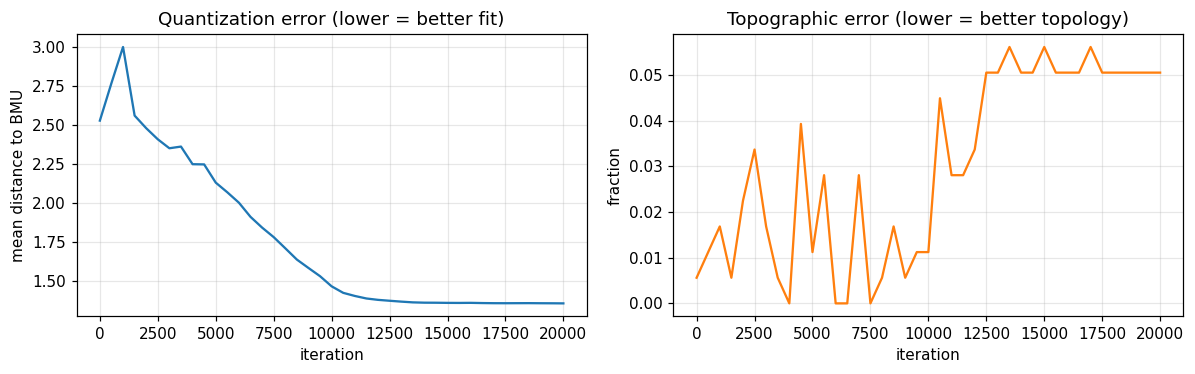

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history.iteration, history.quantization_error, color="tab:blue")
ax[0].set(title="Quantization error (lower = better fit)", xlabel="iteration", ylabel="mean distance to BMU")
ax[1].plot(history.iteration, history.topographic_error, color="tab:orange")
ax[1].set(title="Topographic error (lower = better topology)", xlabel="iteration", ylabel="fraction")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Visualise the trained map

### 6.1 U-Matrix and hit map
- **U-Matrix:** each cell shows the average distance between a neuron and its neighbours. *Dark/low* areas are tight clusters; *bright/high* ridges are boundaries between clusters.
- **Hit map:** how many samples are mapped to each neuron (empty cells are "dead" or interpolating neurons).

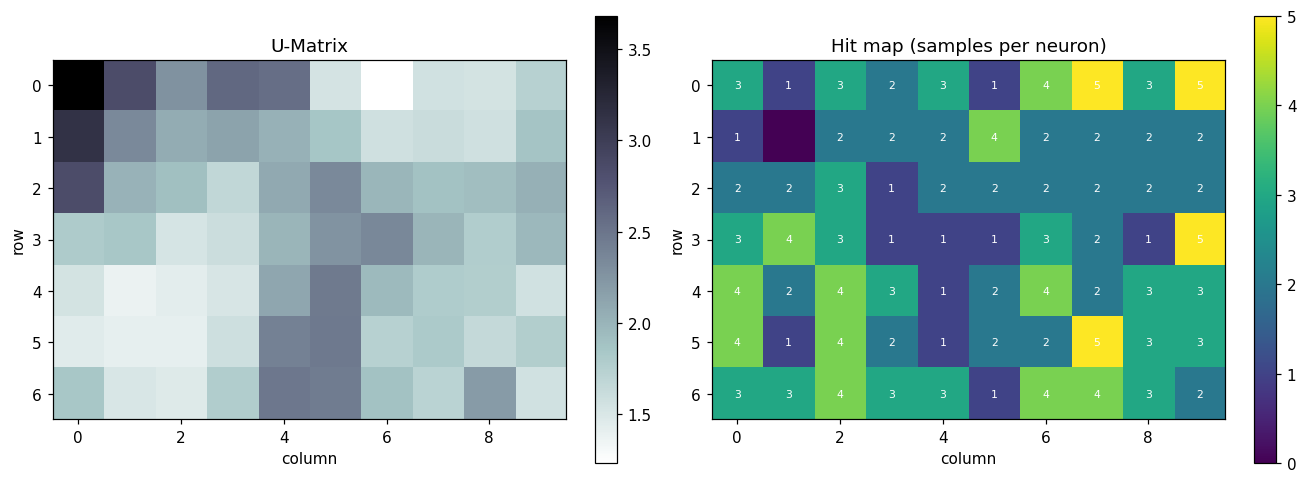

In [9]:
U = som.u_matrix()
H = som.hit_map(X)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
im = ax[0].imshow(U, cmap="bone_r", origin="upper")
ax[0].set_title("U-Matrix"); plt.colorbar(im, ax=ax[0], fraction=.046)
im = ax[1].imshow(H, cmap="viridis", origin="upper")
ax[1].set_title("Hit map (samples per neuron)"); plt.colorbar(im, ax=ax[1], fraction=.046)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if H[i, j] > 0:
            ax[1].text(j, i, H[i, j], ha="center", va="center", color="w", fontsize=7)
for a in ax: a.set(xlabel="column", ylabel="row")
plt.tight_layout(); plt.show()

### 6.2 Component planes
One heat-map per feature, showing the value of that feature's weight at each neuron (in standardised units). Planes that look alike are correlated features; a plane that varies across a region tells you what defines that region.

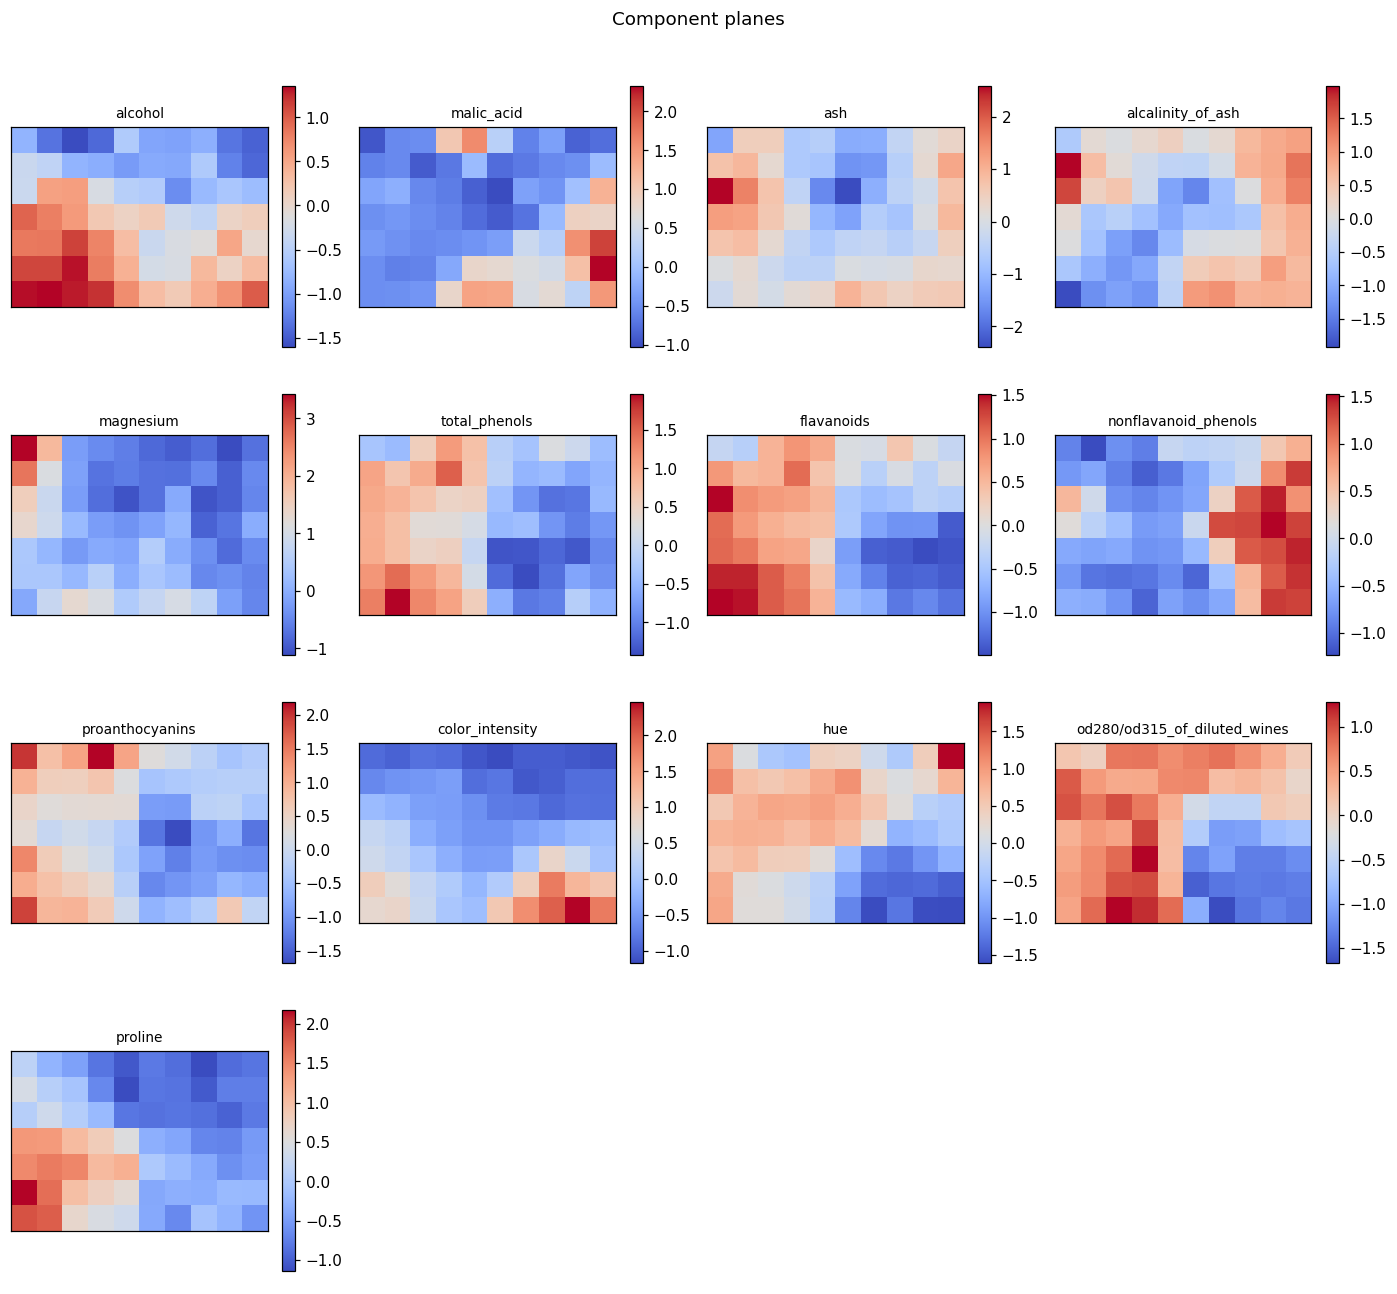

In [10]:
n_cols_plot = min(4, n_features)
n_rows_plot = int(np.ceil(n_features / n_cols_plot))
fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(3.2 * n_cols_plot, 2.9 * n_rows_plot), squeeze=False)
for k, ax in enumerate(axes.ravel()):
    if k < n_features:
        im = ax.imshow(som.weights[:, :, k], cmap="coolwarm", origin="upper")
        ax.set_title(feature_names[k], fontsize=9)
        plt.colorbar(im, ax=ax, fraction=.046)
        ax.set_xticks([]); ax.set_yticks([])
    else:
        ax.axis("off")
plt.suptitle("Component planes", y=1.01)
plt.tight_layout(); plt.show()

## 7. Cluster the map

The SOM compresses the data onto a 2-D grid of prototypes. Running **K-Means on the neuron weight vectors** gives a small number of clusters that are spatially coherent on the map. If `N_CLUSTERS` is `None`, the number of clusters is picked by the best silhouette score.

In [11]:
W = som.weights.reshape(-1, n_features)
bmus = som.bmu_indices(X)
neuron_ids = bmus[:, 0] * som.cols + bmus[:, 1]
occupied = np.unique(neuron_ids)

if N_CLUSTERS is None:
    scores = {}
    for k in range(2, 9):
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(W[occupied])
        scores[k] = silhouette_score(W[occupied], km.labels_)
    N_CLUSTERS = max(scores, key=scores.get)
    print("Silhouette by k:", {k: round(v, 3) for k, v in scores.items()})
print("Chosen number of clusters:", N_CLUSTERS)

km = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit(W)
neuron_cluster = km.labels_.reshape(som.rows, som.cols)
sample_cluster = neuron_cluster[bmus[:, 0], bmus[:, 1]]

print("Samples per cluster:", dict(zip(*np.unique(sample_cluster, return_counts=True))))
print(f"Silhouette on original data: {silhouette_score(X, sample_cluster):.3f}")

Silhouette by k: {2: np.float64(0.303), 3: np.float64(0.32), 4: np.float64(0.29), 5: np.float64(0.259), 6: np.float64(0.29), 7: np.float64(0.223), 8: np.float64(0.252)}
Chosen number of clusters: 3
Samples per cluster: {np.int32(0): np.int64(58), np.int32(1): np.int64(56), np.int32(2): np.int64(64)}
Silhouette on original data: 0.274


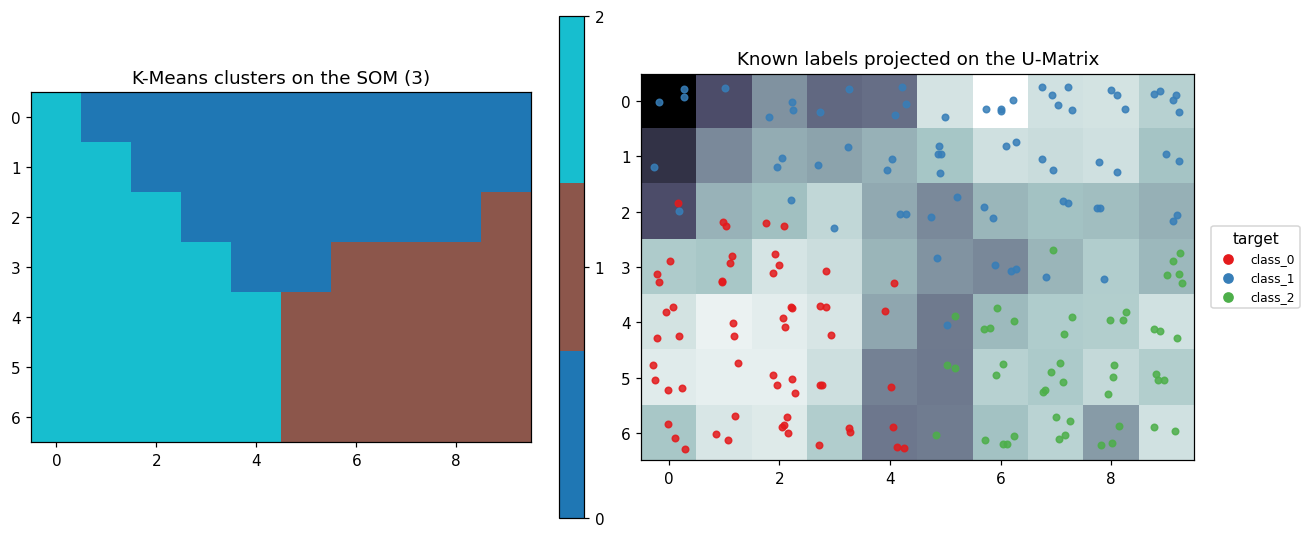

In [12]:
fig, ax = plt.subplots(1, 2 if labels is not None else 1, figsize=(12 if labels is not None else 6, 5), squeeze=False)
ax = ax[0]

cmap = plt.get_cmap("tab10", N_CLUSTERS)
im = ax[0].imshow(neuron_cluster, cmap=cmap, origin="upper")
ax[0].set_title(f"K-Means clusters on the SOM ({N_CLUSTERS})")
cb = plt.colorbar(im, ax=ax[0], fraction=.046, ticks=range(N_CLUSTERS))

if labels is not None:
    # majority known label per neuron (for interpretation only)
    uniq = sorted(set(labels))
    colors = {l: plt.get_cmap("Set1")(i) for i, l in enumerate(uniq)}
    ax[1].imshow(U, cmap="bone_r", origin="upper")
    rng = np.random.default_rng(0)
    for (i, j), l in zip(bmus, labels):
        ax[1].scatter(j + rng.uniform(-.3, .3), i + rng.uniform(-.3, .3), color=colors[l], s=18, alpha=.85)
    for l in uniq:
        ax[1].scatter([], [], color=colors[l], label=l)
    ax[1].legend(title=LABEL_COL, fontsize=8, loc="center left", bbox_to_anchor=(1.02, .5))
    ax[1].set_title("Known labels projected on the U-Matrix")
plt.tight_layout(); plt.show()

### 7.1 Do the unsupervised clusters match the known labels?
Only meaningful if you provided `LABEL_COL`. Labels were **never used for training**, so agreement indicates that the SOM found real structure.

In [13]:
if labels is not None:
    from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
    print(f"Adjusted Rand Index : {adjusted_rand_score(labels, sample_cluster):.3f}")
    print(f"Normalised Mutual Info: {normalized_mutual_info_score(labels, sample_cluster):.3f}\n")
    display(pd.crosstab(pd.Series(sample_cluster, name="SOM cluster"), pd.Series(labels, name=LABEL_COL)))
else:
    print("No label column provided - skipping external validation.")

Adjusted Rand Index : 0.759
Normalised Mutual Info: 0.748



target,class_0,class_1,class_2
SOM cluster,,,
0,1,57,0
1,0,8,48
2,58,6,0


### 7.2 Cluster profiles (mean of the original, un-scaled features)

cluster,0,1,2
alcohol,12.22,13.08,13.65
malic_acid,1.88,3.23,1.97
ash,2.22,2.42,2.46
alcalinity_of_ash,20.02,21.16,17.56
magnesium,90.64,98.71,108.89
total_phenols,2.27,1.71,2.83
flavanoids,2.11,0.88,2.96
nonflavanoid_phenols,0.35,0.45,0.29
proanthocyanins,1.63,1.14,1.95
color_intensity,2.99,6.84,5.38


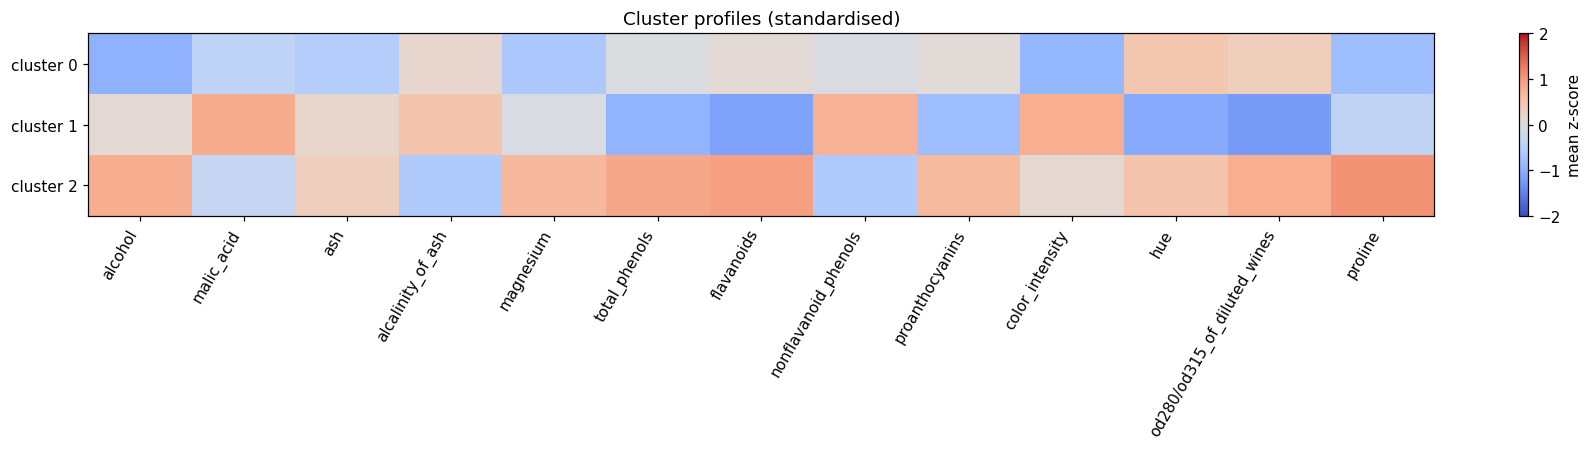

In [14]:
profile = pd.DataFrame(X_raw, columns=feature_names)
profile["cluster"] = sample_cluster
display(profile.groupby("cluster").mean().round(2).T)

# Standardised view: which features stand out in each cluster?
z = pd.DataFrame(X, columns=feature_names).assign(cluster=sample_cluster).groupby("cluster").mean()
fig, ax = plt.subplots(figsize=(1.1 * len(feature_names) + 2, 3 + .4 * N_CLUSTERS))
im = ax.imshow(z.values, cmap="coolwarm", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(feature_names))); ax.set_xticklabels(feature_names, rotation=60, ha="right")
ax.set_yticks(range(N_CLUSTERS)); ax.set_yticklabels([f"cluster {c}" for c in z.index])
plt.colorbar(im, label="mean z-score"); ax.set_title("Cluster profiles (standardised)")
plt.tight_layout(); plt.show()

## 8. Export the results

In [15]:
out = df.copy()
out["som_row"], out["som_col"] = bmus[:, 0], bmus[:, 1]
out["som_cluster"] = sample_cluster
out.to_csv("som_results.csv", index=False)

np.save("som_weights.npy", som.weights)
print("Saved: som_results.csv (data + BMU position + cluster) and som_weights.npy (trained codebook)")
out.head()

Saved: som_results.csv (data + BMU position + cluster) and som_weights.npy (trained codebook)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,som_row,som_col,som_cluster
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,class_0,6,2,2
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,class_0,4,3,2
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,class_0,4,0,2
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,class_0,6,1,2
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,class_0,2,1,2


## 9. Tips for tuning

| Symptom | What to try |
|---|---|
| High topographic error (> ~0.1) | Larger `SIGMA`, more `N_ITERATIONS`, or a smaller grid |
| High quantization error | Larger grid, more iterations |
| Many empty neurons in the hit map | Smaller grid (fewer neurons) |
| Noisy U-Matrix | More iterations; check for outliers / unscaled features |
| Clusters look arbitrary | Set `N_CLUSTERS` manually; inspect the U-Matrix ridges |

**Extensions:** hexagonal grids, batch SOM training, toroidal maps, or comparing with the `MiniSom` library (`pip install minisom`).